# Comparing ramp fitters

`mercupix` has several ramp fitters. This notebook compares their **bias**,
**precision**, **speed** and **robustness to cosmic rays** on simulated ramps
with a known flux. See {doc}`../methods/ramp_fitting` for a summary.

The ramps are simulated directly as active-area arrays (no reference pixels)
with Poisson noise (gain = 1) and Gaussian read noise.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 90

import time
import warnings
import numpy as np
from mercupix.fitter import LSQFit, Brandt2024, Kubik2015

warnings.filterwarnings("ignore", category=RuntimeWarning)   # 0/0 in Brandt's jump search on masked differences

def simulate(flux, ngroups=30, dt=2.8, readnoise=10., npix=64, seed=0):
    """Ramps of shape (ngroups, npix, npix) with a uniform flux [ADU/s]."""
    rng = np.random.default_rng(seed)
    times = np.arange(1, ngroups + 1, dtype="float32") * dt
    counts = np.cumsum(rng.poisson(flux * dt, (ngroups, npix, npix)), axis=0)
    return times, (counts + rng.normal(0, readnoise, counts.shape)).astype("float32")

## Bias and precision

For each flux level, we fit 4096 independent pixels and measure the mean and
the scatter of the fitted slope.

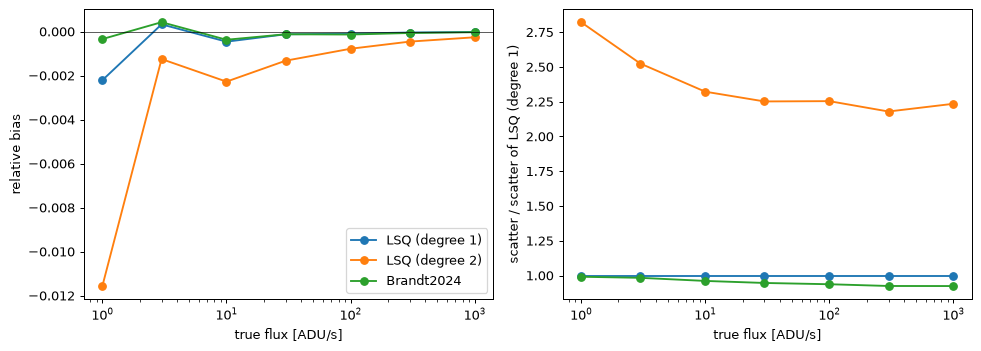

In [2]:
fitters = {
    "LSQ (degree 1)": lambda d, t: LSQFit(d, times=t, degree=1).fit().slope,
    "LSQ (degree 2)": lambda d, t: LSQFit(d, times=t, degree=2).fit().slope,
    "Brandt2024":     lambda d, t: Brandt2024(d, times=t, readnoise=10.).fit().slope,
}
fluxes = np.array([1, 3, 10, 30, 100, 300, 1000])
stats = {name: [] for name in fitters}
for flux in fluxes:
    times, data = simulate(flux)
    for name, fit in fitters.items():
        slope = fit(data, times)
        stats[name].append((slope.mean() - flux, slope.std()))
stats = {name: np.array(v) for name, v in stats.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, s in stats.items():
    axes[0].plot(fluxes, s[:, 0] / fluxes, "o-", label=name)
    axes[1].plot(fluxes, s[:, 1] / stats["LSQ (degree 1)"][:, 1], "o-", label=name)
axes[0].axhline(0, color="k", lw=0.5)
axes[0].set_ylabel("relative bias")
axes[1].set_ylabel("scatter / scatter of LSQ (degree 1)")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("true flux [ADU/s]")
axes[0].legend()
fig.tight_layout()
plt.show()

All fitters are unbiased, within the noise of the 4096 pixels. At low flux,
where read noise dominates, `Brandt2024` and the degree-1 polynomial reach the
same precision. At high flux, photon noise correlates the reads, and the
generalized least-squares weighting of `Brandt2024` gives a scatter up to
~8 % lower than an unweighted polynomial fit.

`LSQFit` returns the slope of the fitted polynomial at `t = 0`. With degree 2,
the polynomial also follows a curved ramp (e.g. classical non-linearity), so
the flux stays unbiased on curved ramps; but `t = 0` lies before the first
read, and extrapolating the slope there makes it 2.2 to 2.8 times noisier
than a straight-line fit. Use degree 2 only when the ramps are curved.

## Speed

In [3]:
times, data = simulate(100, npix=256)
timing = {}
for name, fit in fitters.items():
    fit(data, times)                         # warm-up (imports, caches)
    t0 = time.perf_counter()
    fit(data, times)
    timing[name] = time.perf_counter() - t0
t0 = time.perf_counter()
Brandt2024(data, times=times, readnoise=10.).fit(jumps=True, jump_threshold=[20, 30])
timing["Brandt2024 + jumps"] = time.perf_counter() - t0

for name, t in timing.items():
    print(f"{name:20s} {t * 1e3:8.1f} ms  for {data.shape[1] * data.shape[2]} pixels x {data.shape[0]} groups")

LSQ (degree 1)            9.7 ms  for 65536 pixels x 30 groups
LSQ (degree 2)           11.6 ms  for 65536 pixels x 30 groups
Brandt2024               30.1 ms  for 65536 pixels x 30 groups
Brandt2024 + jumps      237.1 ms  for 65536 pixels x 30 groups


## Robustness to cosmic rays

We add one jump of 1000 ADU at a random group in every pixel, and compare:

- `LSQFit` on the raw ramp,
- `LSQFit` after correcting the jumps with `~mercupix.mask.get_cosmics`
  (*inpainting*, see {doc}`howto_preprocess`),
- `Brandt2024` with jump detection during the fit.

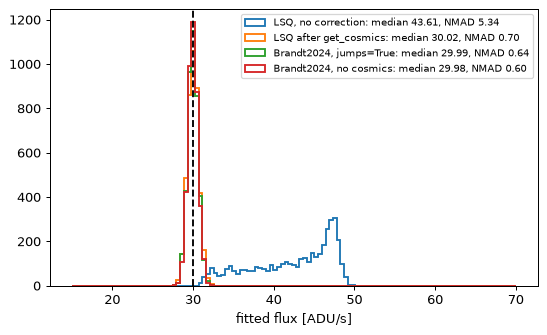

In [4]:
from mercupix.mask import get_cosmics

flux = 30.
times, data = simulate(flux)
rng = np.random.default_rng(1)
hit_group = rng.integers(1, len(times), data.shape[1:])
hit = np.arange(len(times))[:, None, None] >= hit_group[None]
data_cr = data + 1000. * hit

_, inpainted = get_cosmics(data_cr, inpaint=True, cr_threshold_mad=7)
slopes = {
    "LSQ, no correction":      LSQFit(data_cr, times=times, degree=1).fit().slope,
    "LSQ after get_cosmics":   LSQFit(inpainted, times=times, degree=1).fit().slope,
    "Brandt2024, jumps=True":  Brandt2024(data_cr, times=times, readnoise=10.).fit(
                                   jumps=True, jump_threshold=[20, 30]).slope,
    "Brandt2024, no cosmics":  Brandt2024(data, times=times, readnoise=10.).fit().slope,
}

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(flux - 15, flux + 40, 120)
for name, slope in slopes.items():
    ax.hist(slope.ravel(), bins=bins, histtype="step", lw=1.5,
            label=f"{name}: median {np.median(slope):.2f}, NMAD {1.4826 * np.median(np.abs(slope - np.median(slope))):.2f}")
ax.axvline(flux, color="k", ls="--")
ax.set_xlabel("fitted flux [ADU/s]")
ax.legend(fontsize=8)
plt.show()

Without correction, every pixel is biased high. Both strategies remove the
bias. `Brandt2024` keeps the scatter closest to that of a ramp without cosmic
rays; inpainting with `get_cosmics` before an `LSQFit` gives a slightly larger
scatter.

## Kubik2015

`~mercupix.fitter.Kubik2015` estimates the flux from the second moment of
the group differences. It is unbiased and, when photon noise dominates, as
precise as `Brandt2024`; its reported variance, however, overestimates the
scatter when read noise matters:

In [5]:
print(f"{'flux':>6s} {'Kubik flux':>10s} {'scatter':>8s} {'reported':>9s} {'Brandt scatter':>15s}")
for flux in (1., 10., 100., 1000.):
    times, data = simulate(flux)
    res = Kubik2015(data, times=times).fit(readnoise=10.)
    brandt = Brandt2024(data, times=times, readnoise=10.).fit().slope
    print(f"{flux:6.0f} {res.slope.mean():10.2f} {res.slope.std():8.3f} {np.sqrt(res.var.mean()):9.3f} {brandt.std():15.3f}")
print("(ADU/s; 'reported' is the square root of the mean variance returned by fit)")

  flux Kubik flux  scatter  reported  Brandt scatter
     1       1.00    0.211     0.943           0.140
    10      10.00    0.396     1.000           0.368
   100      99.99    1.112     1.452           1.107
  1000     999.97    3.518     3.632           3.518
(ADU/s; 'reported' is the square root of the mean variance returned by fit)
